# Imports Lib 

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Rading the data

In [56]:
df = pd.read_csv('HR_comma_sep.csv')
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


# ***Data exploration and Visulization***

<Axes: xlabel='Department'>

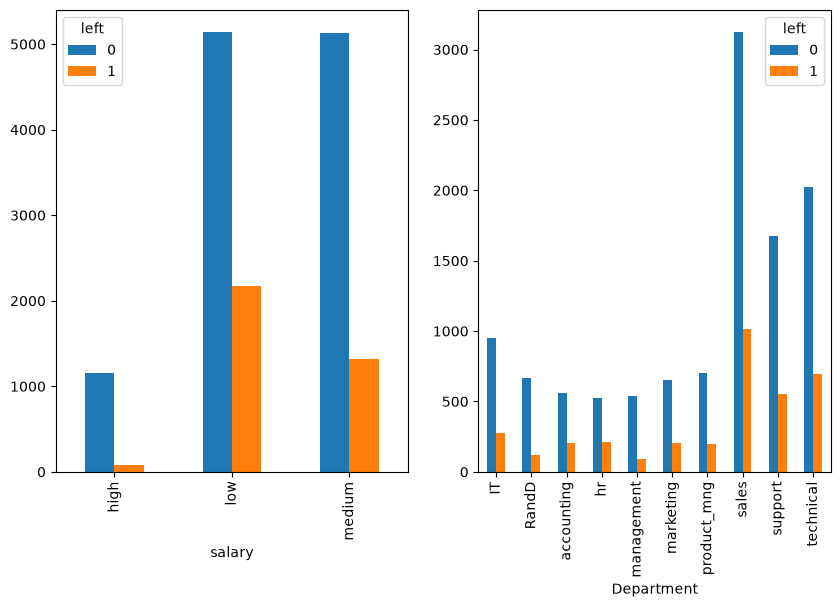

In [57]:
fig, ax = plt.subplots(1,2, figsize=(10, 6))
pd.crosstab(df.salary, df.left).plot(kind='bar', ax=ax[0])
pd.crosstab(df.Department, df.left).plot(kind='bar', ax=ax[1])

In [58]:
left = df[df.left==1]
left.shape

(3571, 10)

In [59]:
retained = df[df.left==0]
retained.shape

(11428, 10)

In [60]:
salary_dummies = pd.get_dummies(df.salary, prefix="salary", dtype=int)
salary_dummies.head()

,salary_high,salary_low,salary_medium
0,0,1,0
1,0,0,1
2,0,0,1
3,0,1,0
4,0,1,0


In [61]:
department_dummies = pd.get_dummies(df.Department, prefix="Department", drop_first=True, dtype=int)
department_dummies.head()

,Department_RandD,Department_accounting,Department_hr,Department_management,Department_marketing,Department_product_mng,Department_sales,Department_support,Department_technical
0,0,0,0,0,0,0,1,0,0
1,0,0,0,0,0,0,1,0,0
2,0,0,0,0,0,0,1,0,0
3,0,0,0,0,0,0,1,0,0
4,0,0,0,0,0,0,1,0,0


#  Average number for all columns

In [62]:
df.groupby('left').mean(numeric_only=True)

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years
left,,,,,,,
0,0.666810,0.715473,3.786664,199.060203,3.380032,0.175009,0.026251
1,0.440098,0.718113,3.855503,207.419210,3.876505,0.047326,0.005321


*Important columns: Satisfaction_level, average_monthly_hours, time_spend_company and salary*

In [63]:
df_new = pd.concat([df[['satisfaction_level', 'average_montly_hours', 'Work_accident', 'promotion_last_5years']], salary_dummies], axis=1)
df_new.head()

,satisfaction_level,average_montly_hours,Work_accident,promotion_last_5years,salary_high,salary_low,salary_medium
0,0.38,157,0,0,0,1,0
1,0.80,262,0,0,0,0,1
2,0.11,272,0,0,0,0,1
3,0.72,223,0,0,0,1,0
4,0.37,159,0,0,0,1,0


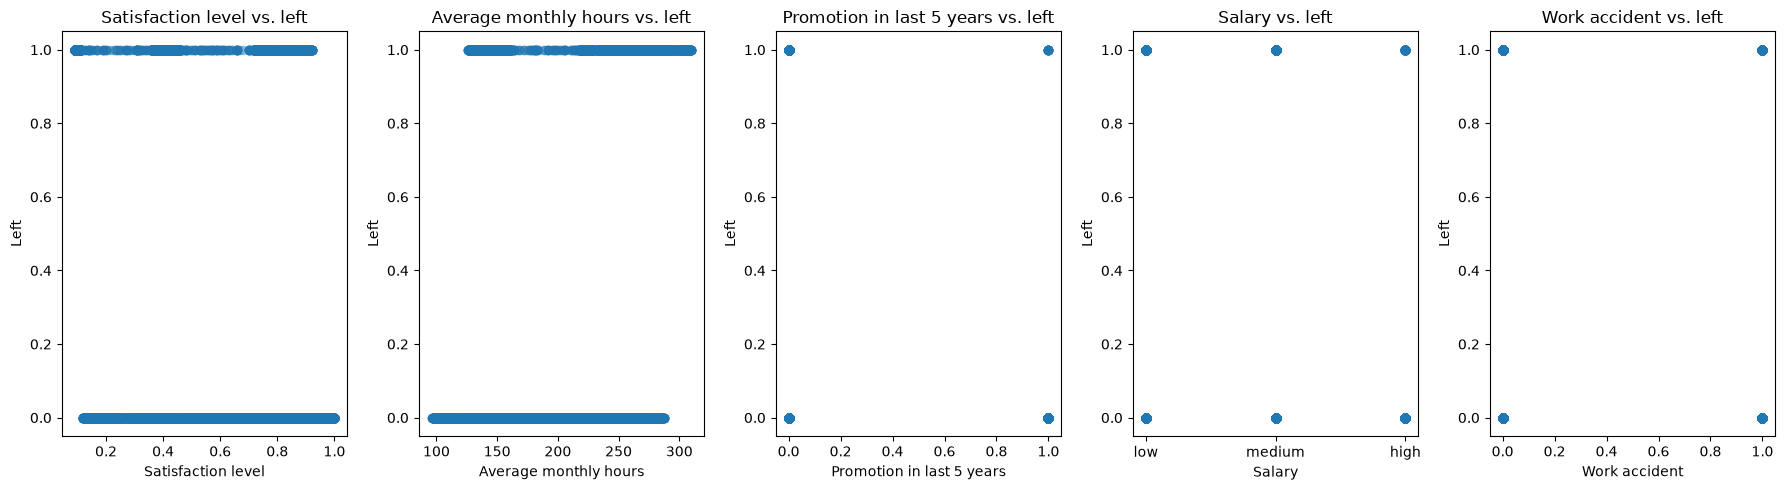

In [64]:
fig, axes = plt.subplots(1, 5, figsize=(18, 5))

axes[0].scatter(df["satisfaction_level"], df["left"], alpha=0.3)
axes[0].set(xlabel="Satisfaction level", ylabel="Left", title="Satisfaction level vs. left")

axes[1].scatter(df["average_montly_hours"], df["left"], alpha=0.3)
axes[1].set(xlabel="Average monthly hours", ylabel="Left", title="Average monthly hours vs. left")

axes[2].scatter(df["promotion_last_5years"], df["left"], alpha=0.3)
axes[2].set(xlabel="Promotion in last 5 years", ylabel="Left", title="Promotion in last 5 years vs. left")

axes[3].scatter(df["salary"], df["left"], alpha=0.3)
axes[3].set(xlabel="Salary", ylabel="Left", title="Salary vs. left")

axes[4].scatter(df.Work_accident, df.left, alpha=0.3)
axes[4].set(xlabel="Work accident", ylabel="Left", title="Work accident vs. left")

plt.tight_layout()
plt.show()

In [65]:
X=df_new
y=df.left

In [79]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)


In [80]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=15000)

In [81]:
from sklearn import set_config
set_config(display="text")
model.fit(X_train, y_train)

LogisticRegression(max_iter=15000)

In [82]:
model.predict(X_test)

array([0, 0, 0, ..., 0, 0, 0], shape=(4500,))

In [83]:
model.score(X_test,y_test)

0.776

# confusion matrix

In [90]:
from sklearn.metrics import confusion_matrix
y_predict = model.predict(X_test)
cm = confusion_matrix(y_test, y_predict)
cm

array([[3206,  208],
       [ 800,  286]])

# Heatmap of confusion matrix

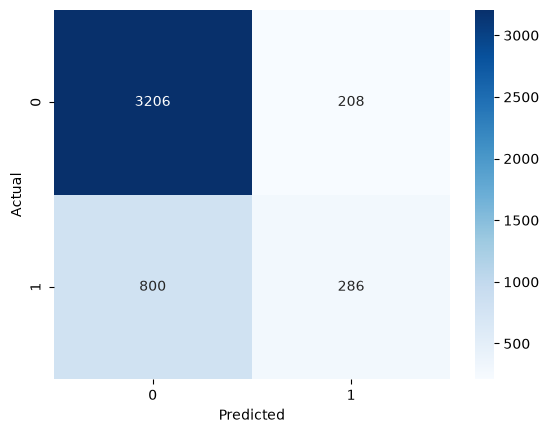

In [93]:
import seaborn as sns
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()